# autocall-pricer — demo

Monte Carlo pricing of a single-underlying autocall and a worst-of under multi-asset Black-Scholes, bump-and-reprice greeks, and validation against QuantLib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from autocall_pricer import (
    Autocall, BlackScholesModel, MonteCarloEngine, WorstOfAutocall,
    compute_greeks, constant_correlation,
)

plt.rcParams['figure.figsize'] = (8, 4)

## 1. Single-underlying autocall

3 years, quarterly observations, early redemption at 100%, 2% coupon per quarter with memory effect, capital protection at 60% (European observation).

In [2]:
model = BlackScholesModel(spots=[100.0], vols=[0.20], rate=0.03, dividends=[0.01])
obs = [0.25 * k for k in range(1, 13)]
autocall = Autocall(obs, autocall_barrier=1.0, coupon=0.02, memory=True, protection_barrier=0.6)

engine = MonteCarloEngine(n_paths=200_000, seed=42, antithetic=True)
res = engine.price(model, autocall)
print(res)

0.990685 ± 0.000509 (95% CI [0.990176, 0.991194], 200000 paths)


### Convergence and 95% confidence interval

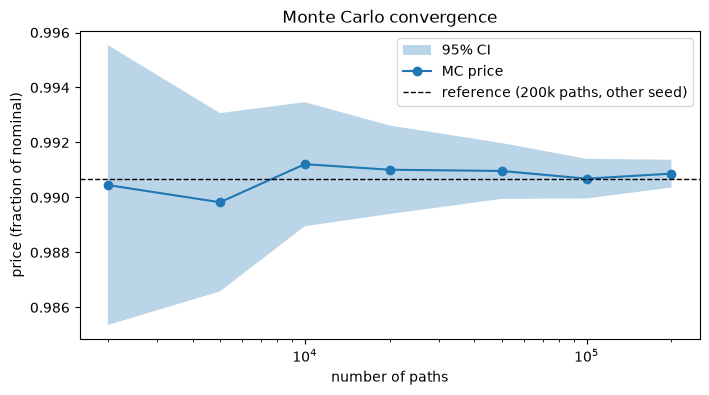

In [3]:
sizes = [2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 200_000]
results = [MonteCarloEngine(n_paths=n, seed=1).price(model, autocall) for n in sizes]
p = np.array([r.price for r in results]); hw = np.array([r.half_width for r in results])
fig, ax = plt.subplots()
ax.fill_between(sizes, p - hw, p + hw, alpha=0.3, label='95% CI')
ax.plot(sizes, p, 'o-', label='MC price')
ax.axhline(res.price, ls='--', c='k', lw=1, label='reference (200k paths, other seed)')
ax.set_xscale('log'); ax.set_xlabel('number of paths'); ax.set_ylabel('price (fraction of nominal)')
ax.legend(); ax.set_title('Monte Carlo convergence');

### Effect of antithetic variates

Effective on a monotonic payoff (call), almost neutral on the autocall, whose payoff is dominated by indicators (early redemption, protection).

In [4]:
from autocall_pricer import EuropeanOption
for name, prod in [('ATM call 1y', EuropeanOption(100.0, 1.0)), ('autocall', autocall)]:
    for anti in (False, True):
        r = MonteCarloEngine(n_paths=100_000, seed=3, antithetic=anti).price(model, prod)
        print(f'{name:14} antithetic={anti!s:5}  price={r.price:.5f}  std error={r.std_error:.5f}')

ATM call 1y    antithetic=False  price=8.83290  std error=0.04316
ATM call 1y    antithetic=True   price=8.79675  std error=0.03273
autocall       antithetic=False  price=0.99055  std error=0.00037
autocall       antithetic=True   price=0.99052  std error=0.00037


### Price and life profile as a function of spot

The initial levels are frozen at 100 (product already issued); the current spot is varied.

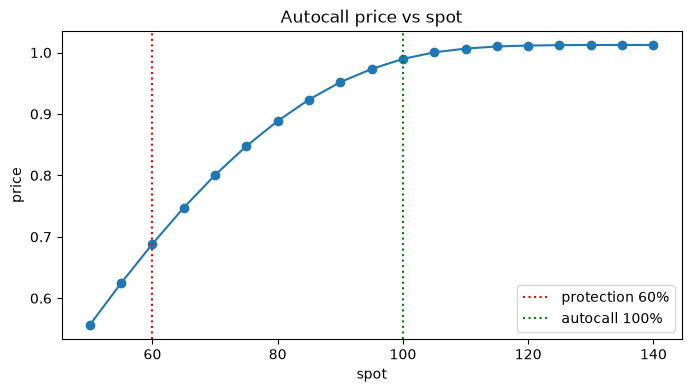

In [5]:
struck = autocall.fixed_at(model.spots)
spots = np.linspace(50, 140, 19)
eng = MonteCarloEngine(n_paths=40_000, seed=7)
prices = [eng.price(model.with_spot(0, s), struck).price for s in spots]
fig, ax = plt.subplots()
ax.plot(spots, prices, 'o-')
ax.axvline(60, ls=':', c='r', label='protection 60%')
ax.axvline(100, ls=':', c='g', label='autocall 100%')
ax.set_xlabel('spot'); ax.set_ylabel('price'); ax.legend(); ax.set_title('Autocall price vs spot');

In [6]:
g = compute_greeks(model, autocall, MonteCarloEngine(n_paths=200_000, seed=42))
print(g.as_table())
print(f'delta for a +1% spot move: {0.01 * model.spots[0] * g.delta[0]:.5f} (in nominal)')
print(f'vega per vol point:        {0.01 * g.vega[0]:.5f}')

price = 0.990685
asset        delta        gamma         vega
    0     0.002523    -0.000148    -0.351470
delta for a +1% spot move: 0.00252 (in nominal)
vega per vol point:        -0.00351


## 2. Worst-of autocall on 3 underlyings

In [7]:
model3 = BlackScholesModel(
    spots=[100.0, 250.0, 40.0], vols=[0.20, 0.25, 0.30], rate=0.03,
    dividends=[0.01, 0.02, 0.0], correlation=constant_correlation(3, 0.6),
)
wo = WorstOfAutocall(obs, assets=(0, 1, 2), autocall_barrier=1.0, coupon=0.025,
                     coupon_barrier=0.7, memory=True, protection_barrier=0.6)
print(engine.price(model3, wo))
gw = compute_greeks(model3, wo, MonteCarloEngine(n_paths=100_000, seed=42))
print(gw.as_table())

0.972397 ± 0.000960 (95% CI [0.971436, 0.973357], 200000 paths)


price = 0.972531
asset        delta        gamma         vega
    0     0.000508    -0.000264    -0.192751
    1     0.000584    -0.000005    -0.363101
    2     0.004700    -0.000312    -0.418539
dP/drho = 0.052461


### Correlation sensitivity

A worst-of is long correlation: the more correlated the underlyings, the less the worst performance is degraded.

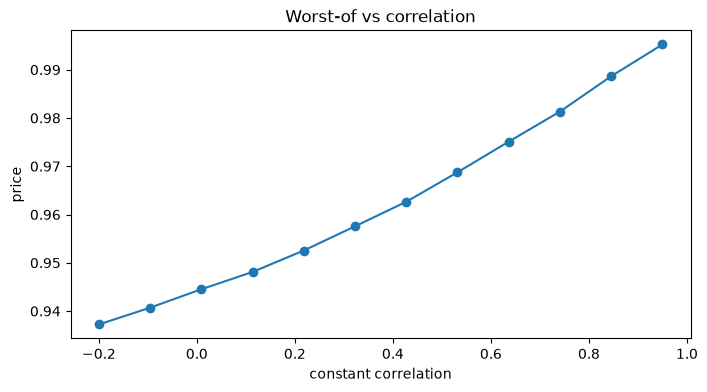

In [8]:
rhos = np.linspace(-0.2, 0.95, 12)
eng = MonteCarloEngine(n_paths=40_000, seed=5)
pr = [eng.price(BlackScholesModel(spots=model3.spots, vols=model3.vols, rate=0.03,
                                 dividends=model3.dividends,
                                 correlation=constant_correlation(3, r)), wo).price for r in rhos]
fig, ax = plt.subplots(); ax.plot(rhos, pr, 'o-')
ax.set_xlabel('constant correlation'); ax.set_ylabel('price'); ax.set_title('Worst-of vs correlation');

### Number of underlyings (2 to 5)

In [9]:
model5 = BlackScholesModel(spots=np.full(5, 100.0), vols=0.25, rate=0.03,
                           correlation=constant_correlation(5, 0.6))
for n in range(1, 6):
    prod = Autocall(obs, coupon=0.025) if n == 1 else WorstOfAutocall(obs, assets=tuple(range(n)), coupon=0.025)
    print(n, 'underlying(s):', engine.price(model5, prod))

1 underlying(s): 0.987003 ± 0.000668 (95% CI [0.986336, 0.987671], 200000 paths)


2 underlying(s): 0.949438 ± 0.000828 (95% CI [0.948610, 0.950266], 200000 paths)


3 underlying(s): 0.918647 ± 0.000882 (95% CI [0.917764, 0.919529], 200000 paths)


4 underlying(s): 0.893204 ± 0.000896 (95% CI [0.892308, 0.894100], 200000 paths)


5 underlying(s): 0.872157 ± 0.000895 (95% CI [0.871262, 0.873052], 200000 paths)


## 3. Validation against QuantLib

In [10]:
from IPython.display import Markdown
from autocall_pricer.validation import run_validation, to_markdown

Markdown(to_markdown(run_validation(n_paths=200_000)))

| Case | QuantLib reference | MC | Std error | QuantLib | Abs. diff | Tolerance | Diff / SE | OK |
|---|---|---:|---:|---:|---:|---:|---:|:---:|
| European call K=100 | AnalyticEuropeanEngine | 8.80548 | 0.02318 | 8.82732 | 0.02184 | 0.07628 | 0.94 | ✅ |
| European put K=90 | AnalyticEuropeanEngine | 2.98335 | 0.01197 | 2.99429 | 0.01094 | 0.03938 | 0.91 | ✅ |
| Digital cash-or-nothing call K=105 | AnalyticEuropeanEngine | 0.39148 | 0.00061 | 0.39171 | 0.00022 | 0.00199 | 0.37 | ✅ |
| Digital cash-or-nothing put K=80 | AnalyticEuropeanEngine | 0.12757 | 0.00068 | 0.12836 | 0.00079 | 0.00222 | 1.17 | ✅ |
| down-and-out call K=100 H=85 (252 obs.) | AnalyticBarrierEngine + BGK | 8.43349 | 0.02401 | 8.44300 | 0.00951 | 0.09588 | 0.40 | ✅ |
| up-and-out put K=100 H=120 (252 obs.) | AnalyticBarrierEngine + BGK | 6.66319 | 0.01549 | 6.66464 | 0.00145 | 0.06430 | 0.09 | ✅ |
| down-and-in put K=100 H=80 (252 obs.) | AnalyticBarrierEngine + BGK | 4.89004 | 0.01875 | 4.88653 | 0.00351 | 0.07148 | 0.19 | ✅ |
| Worst-of call 2 assets K=95 rho=0.5 | StulzEngine | 6.55039 | 0.02209 | 6.55654 | 0.00615 | 0.07269 | 0.28 | ✅ |
| Worst-of call 2 assets K=95 rho=-0.3 | StulzEngine | 2.83677 | 0.01314 | 2.84620 | 0.00942 | 0.04325 | 0.72 | ✅ |
| Autocall 1 date, cpn 8%, protection 70% | QL replication (ZC + digitals + put) | 0.99669 | 0.00014 | 0.99653 | 0.00016 | 0.00047 | 1.14 | ✅ |